# Business Services Industry Intelligence

Financial benchmarking of SIC major group 73 firms over 1994–2025 and analysis of their 2020 and 2025 business disclosures.

## Purpose and contributions

Assess industry performance and changes in disclosure language to support a focused company assessment. Financial data and text data answer complementary questions; neither establishes causation by itself.

| Contributor | Responsibility |
|---|---|
| Fan Yang | Data preparation and integration; focal-company assessment and recommendation |
| Qiaotong (Levia) Zeng | Industry selection and quantitative benchmarking |
| Tina Tory | Text preprocessing, keyword extraction, wordclouds and word2vec |
| All contributors | Interpretation, review and final documentation |

## Structure

1. Data preparation and quality checks
2. Industry scope and financial benchmarking
3. Business disclosure analysis and year comparison
4. Focal-company assessment
5. Limitations and attribution


**Scope:** Business Services is major group **73**. Communications is **48**. The financial and text analyses use major group 73 throughout. Findings below are generated from the current input files when executed.

## Reproduce the analysis

Use Python 3.12 and the package versions in `requirements.txt`. Install the NLTK English stopwords once (`python -m nltk.downloader stopwords`). Place the four CSV files in `data/`, using the exact names shown in the loading cell, then restart the kernel and run all cells in order. Training both word2vec models takes several minutes. Raw datasets are excluded from the repository.

| Project step | Notebook location |
|---|---|
| A — Industry selection and coverage | Sections 1 and 2.1 |
| B — Financial benchmarking | Sections 2.2–2.7 |
| C — Text cleaning | Section 3.1 |
| D — Filing joins, per-firm keywords and wordclouds | Sections 1.2 and 3.2 |
| E — Full-sample word2vec and five neighbors for three terms | Section 3.3 |
| F — Repeat for 2025 and compare | Sections 3.1–3.4 |
| G — One firm, one analytical direction and one suggestion | Section 4 |


## 1 Data preparation and quality checks

### 1.1 Load and standardize source records

Retain raw data, preserve missing financial values, normalize identifiers as strings, standardize dates and location labels, and join industry descriptions. The financial key is `(gvkey, fyear)`. ROA excludes missing income and nonpositive assets.

In [1]:
from pathlib import Path
from collections import Counter
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Run this notebook from the project folder, with the CSVs inside data/.
path = Path("data")

public_raw = pd.read_csv(path / "public_firms.csv", dtype="string")
groups_raw = pd.read_csv(path / "major_groups.csv", dtype="string")

text_raw = {}
text_raw[2020] = pd.read_csv(path / "2020_10K_item1_full.csv", dtype="string")
text_raw[2025] = pd.read_csv(path / "2025_10K_item1_full.csv", dtype="string")

SELECTED_MAJOR_GROUPS = ["73"]
SEED = 508

In [2]:
def tidy_strings(df):
    out = df.copy()
    out.columns = out.columns.str.strip()
    for col in out.columns:
        out[col] = out[col].str.strip().replace("", pd.NA)
    return out

def integer_column(series):
    values = pd.to_numeric(series, errors="raise")
    assert (values.dropna() % 1 == 0).all(), "Unexpected noninteger identifier/code"
    return values.astype("Int64")

def normalize_ids(df):
    out = df.copy()
    out["gvkey"] = integer_column(out["gvkey"]).astype("string").str.zfill(6)
    out["cik"] = integer_column(out["cik"]).astype("string").str.zfill(10)
    return out

public_clean = normalize_ids(tidy_strings(public_raw)).drop_duplicates()
public_clean["fyear"] = integer_column(public_clean["fyear"])
public_clean["sic"] = integer_column(public_clean["sic"]).astype("string").str.zfill(4)
public_clean["major_group"] = public_clean["sic"].str[:2]
public_clean["location"] = public_clean["location"].str.upper()
for col in ["asset", "cash", "net_income", "sale", "prcc_c"]:
    public_clean[col] = pd.to_numeric(public_clean[col], errors="raise").astype("float64")
original_ipo = public_clean["ipodate"].copy()
public_clean["ipodate"] = pd.to_datetime(original_ipo, errors="coerce")
invalid_ipo_dates = public_clean.loc[original_ipo.notna() & public_clean["ipodate"].isna()].copy()
assert public_clean[["gvkey", "cik", "fyear", "sic"]].notna().all().all(), "Missing financial identifier, year or SIC"
assert not public_clean.duplicated(["gvkey", "fyear"]).any()
assert public_clean["fyear"].between(1994, 2025).all()
assert public_clean["sic"].str.fullmatch(r"\d{4}").all()

groups_clean = tidy_strings(groups_raw).drop_duplicates()
groups_clean["major_group"] = integer_column(groups_clean["major_group"]).astype("string").str.zfill(2)
assert not groups_clean["major_group"].duplicated().any()
public_clean = public_clean.merge(groups_clean.rename(columns={"description": "industry_description"}),
                                  on="major_group", how="left", validate="many_to_one")
assert public_clean["industry_description"].notna().all()
# ROA is usable only with nonmissing income and positive assets.
public_clean["roa"] = np.nan
valid_assets = public_clean["asset"] > 0
public_clean.loc[valid_assets, "roa"] = public_clean.loc[valid_assets, "net_income"] / public_clean.loc[valid_assets, "asset"]

missing_summary = public_clean.isna().sum().rename("missing_rows").to_frame()
missing_summary["missing_percent"] = (100 * missing_summary["missing_rows"] / len(public_clean)).round(2)
financial_flags = pd.DataFrame({
    "nonpositive_assets": [public_clean["asset"].le(0).sum()],
    "negative_stock_prices": [public_clean["prcc_c"].lt(0).sum()],
    "invalid_ipo_dates": [len(invalid_ipo_dates)],
})


### 1.2 Integrate filings with financial records

CIK is used to identify the SEC registrant in both datasets, with disagreements between filing and financial GVKEY mappings audited below. Join each filing sample to financial records for its corresponding year. Require one financial record per CIK within that year; an ambiguous mapping raises an error for review instead of multiplying observations. Retain the filing GVKEY separately and audit disagreements with the financial GVKEY.

Remove exact duplicates. When one registrant has multiple nonblank disclosures, keep the longest text with deterministic tie-breaking. This is a stated selection rule, not a claim that the retained filing is latest. Preserve alternatives and unmatched filings for review. The full-sample training corpus also uses one disclosure per CIK to avoid overweighting repeated copies. This includes industries outside Business Services.

In [3]:
combined = {}
full_filings = {}
unmatched_filings = {}
duplicate_candidates = {}
identifier_conflicts = {}
audit_rows = []

for year in (2020, 2025):
    raw = text_raw[year]
    filings = tidy_strings(raw)
    filings = normalize_ids(filings)
    filings["year"] = integer_column(filings["year"])
    assert filings[["cik", "year"]].notna().all().all(), "Missing filing key"
    assert filings["year"].eq(year).all(), "Unexpected filing year"
    exact_duplicates = int(filings.duplicated().sum())
    filings = filings.drop_duplicates().copy()
    filings["text_length"] = filings["item_1"].fillna("").str.len()
    blank_count = int((filings["text_length"] == 0).sum())
    filings = filings[filings["text_length"] > 0].copy()
    filings = filings.rename(columns={"gvkey": "filing_gvkey"})
    duplicate_candidates[year] = filings[filings.duplicated("cik", keep=False)].copy()
    filings = filings.sort_values(["cik", "text_length", "item_1", "filing_gvkey"], ascending=[True, False, True, True])
    filings = filings.drop_duplicates("cik", keep="first").reset_index(drop=True)
    full_filings[year] = filings.copy()
    financial_year = public_clean[public_clean["fyear"] == year].copy()
    assert not financial_year["cik"].duplicated().any(), "Review repeated financial CIKs"
    unmatched_filings[year] = filings[~filings["cik"].isin(financial_year["cik"])].copy()
    matched = filings.merge(financial_year, on="cik", how="inner", validate="one_to_one")
    identifier_conflicts[year] = matched[matched["filing_gvkey"] != matched["gvkey"]].copy()
    assert not matched["gvkey"].duplicated().any()
    combined[year] = matched
    audit_rows.append({"year": year, "raw_rows": len(raw), "exact_duplicates": exact_duplicates,
                       "blank_texts": blank_count, "unique_registrants": len(filings),
                       "unmatched_registrants": len(unmatched_filings[year]),
                       "gvkey_disagreements": len(identifier_conflicts[year]), "matched_firms": len(matched)})

merge_audit = pd.DataFrame(audit_rows)
sector_panel = public_clean[public_clean["major_group"].isin(SELECTED_MAJOR_GROUPS)].copy()
assert not sector_panel.empty, "No firms found in selected industry"
sector_filings = {}
for year in (2020, 2025):
    sector_filings[year] = combined[year][combined[year]["major_group"].isin(SELECTED_MAJOR_GROUPS)].copy()
display(merge_audit, missing_summary, financial_flags)


,year,raw_rows,exact_duplicates,blank_texts,unique_registrants,unmatched_registrants,gvkey_disagreements,matched_firms
0,2020,5481,329,0,4793,674,112,4119
1,2025,4536,0,0,4509,354,0,4155


,missing_rows,missing_percent
gvkey,0,0.00
fyear,0,0.00
conm,0,0.00
cik,0,0.00
ipodate,113695,45.87
sic,0,0.00
asset,8668,3.50
cash,11940,4.82
net_income,9603,3.87
sale,9623,3.88


,nonpositive_assets,negative_stock_prices,invalid_ipo_dates
0,953,0,0


## 2 Industry scope and financial benchmarking

**Lead: Qiaotong Zeng**

All analyses in this section use the selected sector panel, not the full financial dataset. Firm identity is based on GVKEY rather than company name.

### 2.1 Sample coverage

A firm-year observation is a distinct `(gvkey, fyear)` pair, not simply a distinct year. Complete history requires every year from 1994 through 2025.

In [4]:
# The earlier checks restrict years to 1994–2025 and ensure unique firm-year keys.
# Therefore 32 distinct years means every required year is present.
years_per_firm = sector_panel.groupby("gvkey")["fyear"].nunique()
complete_firm_count = int((years_per_firm == 32).sum())
firm_year_count = len(sector_panel[["gvkey", "fyear"]].drop_duplicates())
firm_count = sector_panel["gvkey"].nunique()
sample_summary = pd.DataFrame({"metric": ["Unique firm-years", "Unique firms", "Complete 32-year histories"],
                               "count": [firm_year_count, firm_count, complete_firm_count]})
display(sample_summary)
print("Firm-years:", firm_year_count, "| Firms:", firm_count, "| Complete histories:", complete_firm_count)


,metric,count
0,Unique firm-years,30610
1,Unique firms,3273
2,Complete 32-year histories,64


Firm-years: 30610 | Firms: 3273 | Complete histories: 64


### 2.2 Highest stock prices in 2020 and 2025

Rank nonmissing stock prices separately by year. GVKEY breaks price ties deterministically. Price levels do not measure returns or enterprise value.

In [5]:
top_prices = {}
for year in (2020, 2025):
    top_prices[year] = (sector_panel.loc[sector_panel["fyear"] == year]
        .dropna(subset=["prcc_c"]).sort_values(["prcc_c", "gvkey"], ascending=[False, True])
        [["gvkey", "conm", "fyear", "prcc_c"]].head(10))
    display(Markdown(f"**{year} stock-price ranking**"), top_prices[year])
    if not top_prices[year].empty:
        lead = top_prices[year].iloc[0]
        display(Markdown(f"{lead['conm']} has the highest observed stock price in {year}: **{lead['prcc_c']:,.2f}** in source price units."))


**2020 stock-price ranking**

,gvkey,conm,fyear,prcc_c
213155,160329,ALPHABET INC,2020,1752.64
223284,174302,CONSTELLATION SOFTWARE INC,2020,1303.04
88895,023650,SHOPIFY INC,2020,1131.95
182520,112111,COSTAR GROUP INC,2020,924.28
105041,027885,TRADE DESK INC,2020,801.00
222619,171007,SERVICENOW INC,2020,550.43
57718,013824,FAIR ISAAC CORP,2020,511.04
50774,012540,ADOBE INC,2020,500.12
79706,020116,PAYCOM SOFTWARE INC,2020,452.25
42516,010789,TYLER TECHNOLOGIES INC,2020,436.52


ALPHABET INC has the highest observed stock price in 2020: **1,752.64** in source price units.

**2025 stock-price ranking**

,gvkey,conm,fyear,prcc_c
223289,174302,CONSTELLATION SOFTWARE INC,2025,2399.743
57723,013824,FAIR ISAAC CORP,2025,1690.620
172492,066065,UNITED RENTALS INC,2025,809.320
136812,038212,APPLOVIN CORP,2025,673.820
105385,027928,INTUIT INC,2025,662.420
222074,170617,META PLATFORMS INC,2025,660.090
129013,033175,SPOTIFY TECHNOLOGY SA,2025,580.710
212978,160225,MASTERCARD INC,2025,570.880
7177,002596,CACI INTL INC -CL A,2025,532.810
26815,007163,S&P GLOBAL INC,2025,522.590


CONSTELLATION SOFTWARE INC has the highest observed stock price in 2025: **2,399.74** in source price units.

### 2.3 Highest historical annual sales

Interpret the historical ranking as each firm's highest observed annual sales, rather than cumulative sales. Retain the peak year and rank unique firms.

In [6]:
peak_sales = (sector_panel.dropna(subset=["sale"])
    .sort_values(["sale", "gvkey", "fyear"], ascending=[False, True, False])
    .drop_duplicates("gvkey")[["gvkey", "conm", "fyear", "sale"]].head(10))
display(peak_sales)
if not peak_sales.empty:
    lead = peak_sales.iloc[0]
    display(Markdown(f"{lead['conm']} records the highest observed annual sales: **{lead['sale']:,.2f}** in {lead['fyear']} (source monetary units)."))


,gvkey,conm,fyear,sale
213160,160329,ALPHABET INC,2025,402836.000
48616,012141,MICROSOFT CORP,2025,281724.000
222074,170617,META PLATFORMS INC,2025,200966.000
21959,006066,INTL BUSINESS MACHINES CORP,2011,106916.000
48648,012142,ORACLE CORP,2025,67357.000
74388,018467,FUJITSU LTD,2010,54717.315
29061,007652,NEC CORP,1999,48460.650
177159,103487,SAP SE,2025,43207.817
212174,157855,SALESFORCE INC,2025,41525.000
153481,062599,LUCENT TECHNOLOGIES INC,1999,38303.000


ALPHABET INC records the highest observed annual sales: **402,836.00** in 2025 (source monetary units).

### 2.4 Geographical distribution

Assign each firm its latest nonmissing observed location. Count each GVKEY once so repeated years and firms that move do not inflate location totals.

In [7]:
firm_locations = (sector_panel.dropna(subset=["location"]).sort_values(["gvkey", "fyear"])
                  .drop_duplicates("gvkey", keep="last"))
location_counts = firm_locations.groupby("location")["gvkey"].nunique().sort_values(ascending=False)
display(location_counts.head(10).rename("unique_firms").to_frame())
if not location_counts.empty:
    display(Markdown(f"**{location_counts.index[0]}** is the most frequent recorded location, with **{location_counts.iloc[0]:,}** firms. Firms with no recorded location are excluded."))


,unique_firms
location,
USA,2684
CHN,152
CAN,80
ISR,76
GBR,56
HKG,39
SGP,33
JPN,22
IRL,15


**USA** is the most frequent recorded location, with **2,684** firms. Firms with no recorded location are excluded.

### 2.5 Average stock price across years

Plot the arithmetic mean of observed prices and show the number of contributing firms. Coverage changes, stock splits and extreme prices may affect the trend.

,mean_price,observations
fyear,,
1994,12.607722,526
1995,15.874570,678
1996,14.427411,875
1997,14.501933,950
1998,15.497616,990
1999,28.035005,1188
2000,10.555017,1233
2001,9.352093,1112
2002,7.011882,1037


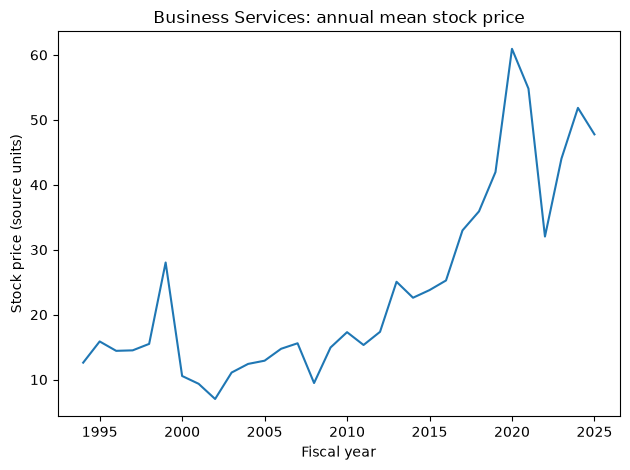

Observed mean prices are **12.61** in 1994 and **47.77** in 2025. This comparison describes price levels, not investor returns.

In [8]:
annual_prices = sector_panel.groupby("fyear")["prcc_c"].agg(mean_price="mean", observations="count")
display(annual_prices)
fig, ax = plt.subplots()
ax.plot(annual_prices.index, annual_prices["mean_price"])
ax.set(title="Business Services: annual mean stock price", xlabel="Fiscal year", ylabel="Stock price (source units)")
fig.tight_layout()
plt.show()
valid = annual_prices["mean_price"].dropna()
if not valid.empty:
    display(Markdown(f"Observed mean prices are **{valid.iloc[0]:,.2f}** in {valid.index[0]} and **{valid.iloc[-1]:,.2f}** in {valid.index[-1]}. This comparison describes price levels, not investor returns."))


### 2.6 Largest stock-price decline from 2007 to 2008

Match prices by GVKEY; require a positive 2007 price and a nonmissing, nonnegative 2008 price. The observed change is not proof that the crisis caused that firm's decline.

In [9]:
prices_2007 = sector_panel[sector_panel["fyear"] == 2007][["gvkey", "prcc_c"]].copy()
prices_2007 = prices_2007.rename(columns={"prcc_c": "price_2007"})
prices_2008 = sector_panel[sector_panel["fyear"] == 2008][["gvkey", "conm", "prcc_c"]].copy()
prices_2008 = prices_2008.rename(columns={"prcc_c": "price_2008"})
crisis_prices = prices_2007.merge(prices_2008, on="gvkey", how="inner", validate="one_to_one")
crisis_prices = crisis_prices.dropna(subset=["price_2007", "price_2008"])
crisis_prices = crisis_prices[(crisis_prices["price_2007"] > 0) & (crisis_prices["price_2008"] >= 0)].copy()
crisis_prices["change_percent"] = 100 * (crisis_prices["price_2008"] / crisis_prices["price_2007"] - 1)
largest_decline = crisis_prices.sort_values("change_percent").head(1)
display(largest_decline)
if not largest_decline.empty:
    lead = largest_decline.iloc[0]
    print(lead["conm"], "price change:", round(lead["change_percent"], 2), "%")


,gvkey,price_2007,conm,price_2008,change_percent
699,183139,1.25,ACCESS NEWSWIRE INC,0.0071,-99.432


ACCESS NEWSWIRE INC price change: -99.43 %


### 2.7 Average ROA for USA firms

Calculate valid firm-year ratios first, then take their arithmetic mean. This is not the ratio of aggregate income to aggregate assets; small positive assets may still produce influential extreme ratios.

,mean_roa,observations
fyear,,
1994,-0.186495,683
1995,-0.170119,891
1996,-0.214454,967
1997,0.011134,1030
1998,-0.726496,1245
1999,-0.493370,1262
2000,-0.977971,1155
2001,-3.889728,1033
2002,-6.221008,958


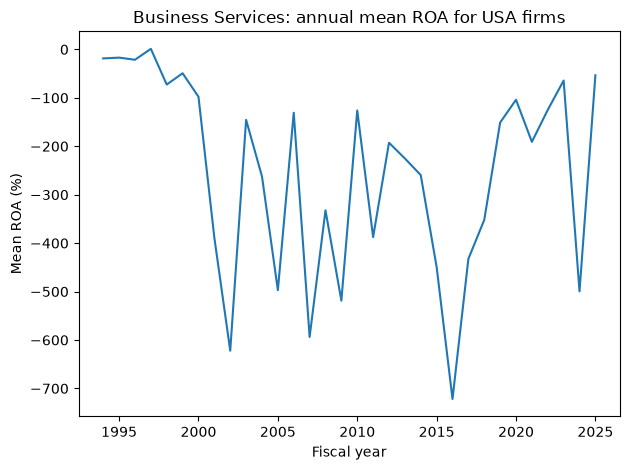

Mean valid ROA is **-18.65%** in 1994 and **-53.43%** in 2025. Review annual coverage and extreme ratios before interpreting the trend.

In [10]:
usa_sector = sector_panel.loc[sector_panel["location"] == "USA"].copy()
annual_roa = usa_sector.groupby("fyear")["roa"].agg(mean_roa="mean", observations="count")
display(annual_roa)
fig, ax = plt.subplots()
ax.plot(annual_roa.index, 100 * annual_roa["mean_roa"])
ax.set(title="Business Services: annual mean ROA for USA firms", xlabel="Fiscal year", ylabel="Mean ROA (%)")
fig.tight_layout()
plt.show()
valid = annual_roa["mean_roa"].dropna()
if not valid.empty:
    display(Markdown(f"Mean valid ROA is **{100 * valid.iloc[0]:.2f}%** in {valid.index[0]} and **{100 * valid.iloc[-1]:.2f}%** in {valid.index[-1]}. Review annual coverage and extreme ratios before interpreting the trend."))


## 3 Business disclosure analysis

**Lead: Tina Tory**

The following implementation consolidates Tina's cleaning, frequency, TF-IDF, wordcloud and embedding workflow. A common configuration keeps both years consistent.

### 3.1 Text preprocessing

Use lowercase text, replace punctuation with spaces, and remove NLTK English stop words. Preserve original disclosures. Numeric tokens are retained in the cleaned column but excluded consistently from keyword analysis and embeddings, which use alphabetic tokens. No stemming or lemmatization is applied.

In [11]:
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud
from gensim.models import Word2Vec

stop_words = set(stopwords.words("english"))

def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = re.sub(r"[^\w\s]|_", " ", text)
    kept_words = []
    for word in text.split():
        if word not in stop_words:
            kept_words.append(word)
    return " ".join(kept_words)

def word_tokens(text):
    words = []
    for word in text.split():
        if word.isalpha():
            words.append(word)
    return words

for year in (2020, 2025):
    full_filings[year]["item_1_clean"] = full_filings[year]["item_1"].apply(clean_text)
    sector_filings[year]["item_1_clean"] = sector_filings[year]["item_1"].apply(clean_text)
    sector_filings[year]["tokens"] = sector_filings[year]["item_1_clean"].apply(word_tokens)
    print("Cleaned full-sample and sector disclosures for", year)
 


Cleaned full-sample and sector disclosures for 2020
Cleaned full-sample and sector disclosures for 2025


### 3.2 Keyword analysis

#### 3.2.1 Sector sample and merge validation

Use the validated CIK joins from Section 1. Each selected firm has one disclosure per year. Report coverage separately because a firm may lack a matched filing. Empty alphabetic documents are omitted from keyword calculations, with their count reported.

In [12]:
nlp_samples = {}
coverage_rows = []
for year, df in sector_filings.items():
    assert not df["cik"].duplicated().any()
    nlp_samples[year] = df.loc[df["tokens"].str.len() > 0].reset_index(drop=True)
    coverage_rows.append({"year": year,
                         "sector_financial_firms": sector_panel.loc[sector_panel["fyear"] == year, "gvkey"].nunique(),
                         "matched_filings": len(df), "empty_token_documents": len(df) - len(nlp_samples[year]),
                         "keyword_documents": len(nlp_samples[year])})
    assert not nlp_samples[year].empty, f"No usable sector disclosures for {year}"
nlp_coverage = pd.DataFrame(coverage_rows)
display(nlp_coverage)


,year,sector_financial_firms,matched_filings,empty_token_documents,keyword_documents
0,2020,880,477,0,477
1,2025,765,510,0,510


#### 3.2.2 Top ten keywords per firm using word counts

Rank terms within each company's disclosure. This satisfies the per-firm requirement; pooled sector counts alone do not. Ties are broken alphabetically. Documents with fewer than ten distinct terms return only available terms.

In [13]:
count_results = {}
sector_word_counts = {}
for year in (2020, 2025):
    sample = nlp_samples[year]
    records = []
    total_counts = Counter()
    for row_number, firm in sample.iterrows():
        counts = Counter(firm["tokens"])
        total_counts.update(counts)
        ranking = pd.DataFrame(list(counts.items()), columns=["term", "count"])
        ranking = ranking.sort_values(["count", "term"], ascending=[False, True]).head(10)
        rank = 1
        for term_row, result in ranking.iterrows():
            records.append({"year": year, "gvkey": firm["gvkey"], "cik": firm["cik"],
                            "conm": firm["conm"], "rank": rank, "term": result["term"], "count": result["count"]})
            rank = rank + 1
    count_results[year] = pd.DataFrame(records)
    sector_word_counts[year] = total_counts
    print("Per-firm counts for", year, "(first 30 rows)")
    display(count_results[year].head(30))
firm_keyword_counts = pd.concat([count_results[2020], count_results[2025]], ignore_index=True)


Per-firm counts for 2020 (first 30 rows)


,year,gvkey,cik,conm,rank,term,count
0,2020,001084,0000001961,WORLDS INC,1,worlds,33
1,2020,001084,0000001961,WORLDS INC,2,inc,20
2,2020,001084,0000001961,WORLDS INC,3,technology,17
3,2020,001084,0000001961,WORLDS INC,4,user,16
4,2020,001084,0000001961,WORLDS INC,5,company,14
5,2020,001084,0000001961,WORLDS INC,6,patent,14
6,2020,001084,0000001961,WORLDS INC,7,patents,14
7,2020,001084,0000001961,WORLDS INC,8,virtual,14
8,2020,001084,0000001961,WORLDS INC,9,online,10
9,2020,001084,0000001961,WORLDS INC,10,users,10


Per-firm counts for 2025 (first 30 rows)


,year,gvkey,cik,conm,rank,term,count
0,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,1,adp,117
1,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,2,solutions,86
2,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,3,services,79
3,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,4,clients,74
4,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,5,management,53
5,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,6,hcm,52
6,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,7,data,47
7,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,8,payroll,46
8,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,9,ai,42
9,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,10,business,42


#### 3.2.3 Top ten keywords per firm using TF-IDF

Each firm's disclosure is a document. Use alphabetic tokens and L2-normalized TF-IDF with smoothed IDF. Fit each year's sector corpus separately for within-year rankings. Sector wordcloud weights are the mean TF-IDF across all documents, including zeros.

In [14]:
tfidf_results = {}
sector_tfidf = {}
for year in (2020, 2025):
    sample = nlp_samples[year]
    vectorizer = TfidfVectorizer(analyzer=word_tokens)
    matrix = vectorizer.fit_transform(sample["item_1_clean"])
    terms = vectorizer.get_feature_names_out()
    records = []
    for row_number, firm in sample.iterrows():
        # Convert only one firm's scores to an ordinary array, not the entire matrix.
        scores = matrix[row_number].toarray().ravel()
        ranking = pd.DataFrame({"term": terms, "tfidf": scores})
        ranking = ranking[ranking["tfidf"] > 0]
        ranking = ranking.sort_values(["tfidf", "term"], ascending=[False, True]).head(10)
        rank = 1
        for term_row, result in ranking.iterrows():
            records.append({"year": year, "gvkey": firm["gvkey"], "cik": firm["cik"],
                            "conm": firm["conm"], "rank": rank, "term": result["term"], "tfidf": result["tfidf"]})
            rank = rank + 1
    tfidf_results[year] = pd.DataFrame(records)
    mean_scores = np.asarray(matrix.mean(axis=0)).ravel()
    sector_tfidf[year] = pd.Series(mean_scores, index=terms).sort_values(ascending=False)
    print("Per-firm TF-IDF for", year, "(first 30 rows)")
    display(tfidf_results[year].head(30))
firm_keyword_tfidf = pd.concat([tfidf_results[2020], tfidf_results[2025]], ignore_index=True)


Per-firm TF-IDF for 2020 (first 30 rows)


,year,gvkey,cik,conm,rank,term,tfidf
0,2020,001084,0000001961,WORLDS INC,1,worlds,0.646339
1,2020,001084,0000001961,WORLDS INC,2,worldsplayer,0.270771
2,2020,001084,0000001961,WORLDS INC,3,avatars,0.189540
3,2020,001084,0000001961,WORLDS INC,4,worldsshaper,0.189540
4,2020,001084,0000001961,WORLDS INC,5,bungie,0.162463
5,2020,001084,0000001961,WORLDS INC,6,partes,0.145075
6,2020,001084,0000001961,WORLDS INC,7,petitions,0.127687
7,2020,001084,0000001961,WORLDS INC,8,ptab,0.120896
8,2020,001084,0000001961,WORLDS INC,9,virtual,0.119043
9,2020,001084,0000001961,WORLDS INC,10,linden,0.108308


Per-firm TF-IDF for 2025 (first 30 rows)


,year,gvkey,cik,conm,rank,term,tfidf
0,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,1,adp,0.765720
1,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,2,hcm,0.312352
2,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,3,payroll,0.175713
3,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,4,hr,0.167076
4,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,5,clients,0.160418
5,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,6,solutions,0.126073
6,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,7,services,0.106030
7,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,8,associates,0.105898
8,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,9,peo,0.098169
9,2025,001891,0000008670,AUTOMATIC DATA PROCESSING,10,client,0.095331


#### 3.2.4 Wordclouds and sector rankings

Produce count and mean TF-IDF wordclouds for each year. Their sizes encode different statistics and should not be compared numerically across methods. Use fixed seeds for the visual layouts.

**2020: sector top ten terms**

,term,count
0,services,13395
1,business,13322
2,customers,10884
3,data,10308
4,solutions,8966
5,company,8793
6,products,7437
7,may,7148
8,including,7043
9,management,7036


,mean_tfidf
services,0.067791
customers,0.061014
business,0.060261
data,0.051899
solutions,0.050355
company,0.046614
products,0.038450
platform,0.037984
customer,0.037317
software,0.036032


**2025: sector top ten terms**

,term,count
0,data,14604
1,services,13043
2,customers,11902
3,business,11892
4,company,10360
5,platform,10032
6,solutions,9342
7,including,8763
8,technology,7973
9,also,7790


,mean_tfidf
data,0.062481
services,0.059467
customers,0.059104
business,0.052394
solutions,0.047549
platform,0.045233
company,0.042390
including,0.037690
customer,0.036997
information,0.036075


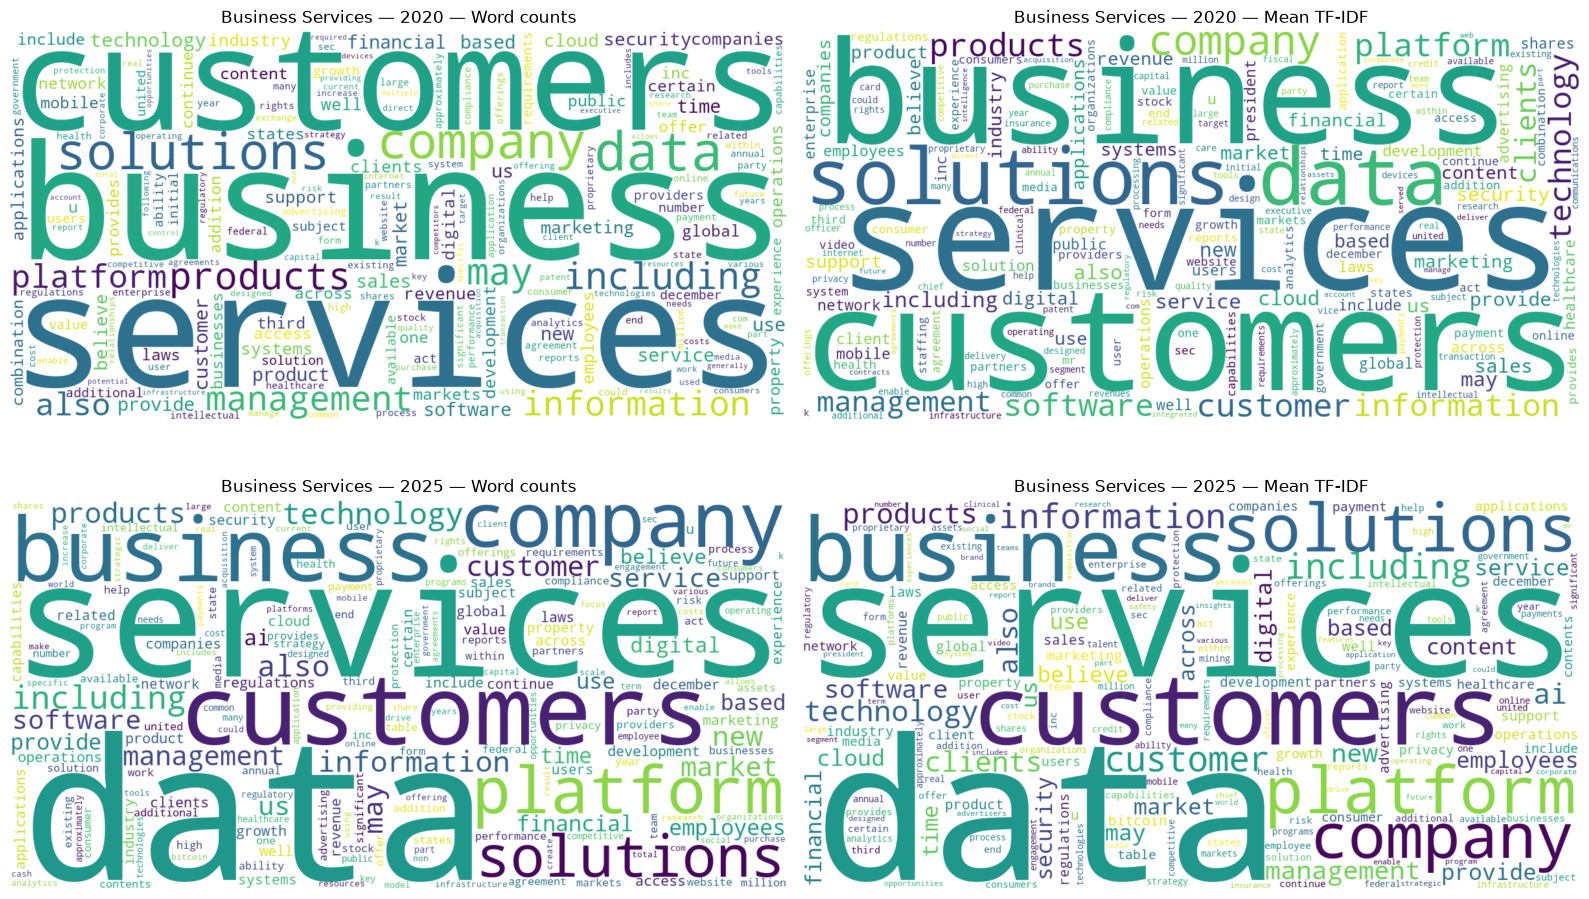

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for row, year in enumerate((2020, 2025)):
    weights = [sector_word_counts[year], sector_tfidf[year].to_dict()]
    for column, (method, frequencies) in enumerate(zip(["Word counts", "Mean TF-IDF"], weights)):
        cloud = WordCloud(width=1200, height=600, background_color="white", collocations=False,
                          random_state=SEED).generate_from_frequencies(frequencies)
        axes[row, column].imshow(cloud, interpolation="bilinear")
        axes[row, column].set_title(f"Business Services — {year} — {method}")
        axes[row, column].axis("off")
    display(Markdown(f"**{year}: sector top ten terms**"),
            pd.DataFrame(sector_word_counts[year].most_common(10), columns=["term", "count"]),
            sector_tfidf[year].head(10).rename("mean_tfidf").to_frame())
fig.tight_layout()
plt.show()


### 3.3 Word embeddings

#### 3.3.1 Full-sample word2vec training

Train separate models on the full, cleaned cross-industry sample for each year, not just the selected sector. Each disclosure is split into consecutive chunks of up to 1,000 alphabetic tokens so very long documents do not exceed the trainer’s internal sequence limit. Chunk boundaries omit a small number of cross-boundary contexts; the model otherwise uses local five-token windows. Identical parameters and a single worker improve reproducibility. Fixed seeds do not guarantee identical results across all software versions.

In [16]:
w2v_models = {}
model_summary = []
CHUNK_SIZE = 1000
for year in (2020, 2025):
    corpus = []
    document_count = 0
    for text in full_filings[year]["item_1_clean"]:
        tokens = word_tokens(text)
        if len(tokens) > 0:
            document_count = document_count + 1
            for start in range(0, len(tokens), CHUNK_SIZE):
                corpus.append(tokens[start:start + CHUNK_SIZE])
    # A list of token lists is the basic format expected by word2vec.
    model = Word2Vec(sentences=corpus, vector_size=100, window=5, min_count=5,
                     workers=1, seed=SEED, epochs=5)
    w2v_models[year] = model
    model_summary.append({"year": year, "training_documents": document_count, "training_chunks": len(corpus), "vocabulary_size": len(model.wv)})
    del corpus
    print("Finished word2vec training for", year)
display(pd.DataFrame(model_summary))


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Finished word2vec training for 2020


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Finished word2vec training for 2025


,year,training_documents,training_chunks,vocabulary_size
0,2020,4793,25981,54260
1,2025,4509,28068,54771


#### 3.3.2 Representative terms and nearest neighbors

Visual inspection of the regenerated wordclouds supports services (service provision), software (technology offerings) and customers (customer relationships) as three relevant themes. Software is less dominant than services/customers, but is visible in both years and ranks in the 2020 mean TF-IDF top ten. All three are compared using the same year-specific models. Vocabulary gaps are reported explicitly.

In [17]:
QUERY_KEYWORDS = ["services", "software", "customers"]
neighbor_rows = []
for year, model in w2v_models.items():
    for keyword in QUERY_KEYWORDS:
        if keyword not in model.wv:
            neighbor_rows.append({"year": year, "keyword": keyword, "rank": pd.NA,
                                  "neighbor": "Out of vocabulary", "cosine_similarity": np.nan})
            continue
        for rank, (neighbor, similarity) in enumerate(model.wv.most_similar(keyword, topn=5), 1):
            neighbor_rows.append({"year": year, "keyword": keyword, "rank": rank,
                                  "neighbor": neighbor, "cosine_similarity": similarity})
similarity_results = pd.DataFrame(neighbor_rows)
display(similarity_results)


,year,keyword,rank,neighbor,cosine_similarity
0,2020,services,1,solutions,0.663005
1,2020,services,2,service,0.651612
2,2020,services,3,assistance,0.541118
3,2020,services,4,clients,0.539970
4,2020,services,5,ancillary,0.533079
5,2020,software,1,hardware,0.789778
6,2020,software,2,middleware,0.734879
7,2020,software,3,integrations,0.685974
8,2020,software,4,sdk,0.683982
9,2020,software,5,firmware,0.676541


### 3.4 Comparison of 2020 and 2025

The pipeline applies the same preprocessing and settings to both years. Compare normalized token shares and ranks rather than unadjusted counts alone. Independent TF-IDF fits have different IDF weights, so their rankings describe relative emphasis within each year; score changes are not a controlled measure of change. Sample composition and disclosure length may explain apparent differences.

In [18]:
token_shares = {}
for year in (2020, 2025):
    counts = sector_word_counts[year]
    token_shares[year] = pd.Series(counts, dtype="float64") / sum(counts.values())
term_comparison = pd.concat([token_shares[2020], token_shares[2025]], axis=1).fillna(0)
term_comparison.columns = ["share_2020", "share_2025"]
term_comparison["change_percentage_points"] = 100 * (term_comparison["share_2025"] - term_comparison["share_2020"])
important_terms = set()
for year in (2020, 2025):
    for term, count in sector_word_counts[year].most_common(10):
        important_terms.add(term)
display(term_comparison.loc[sorted(important_terms)].sort_values("change_percentage_points", ascending=False))

ranks_2020 = sector_tfidf[2020].rank(method="min", ascending=False)
ranks_2025 = sector_tfidf[2025].rank(method="min", ascending=False)
rank_comparison = pd.concat([ranks_2020, ranks_2025], axis=1)
rank_comparison.columns = ["rank_2020", "rank_2025"]
selected_terms = set(sector_tfidf[2020].head(10).index) | set(sector_tfidf[2025].head(10).index)
display(rank_comparison.loc[sorted(selected_terms)])
common_ciks = set(nlp_samples[2020]["cik"]) & set(nlp_samples[2025]["cik"])
print("2020 firms:", len(nlp_samples[2020]), "| 2025 firms:", len(nlp_samples[2025]), "| Common firms:", len(common_ciks))
for keyword in QUERY_KEYWORDS:
    neighbors_2020 = similarity_results[(similarity_results["year"] == 2020) & (similarity_results["keyword"] == keyword)]
    neighbors_2025 = similarity_results[(similarity_results["year"] == 2025) & (similarity_results["keyword"] == keyword)]
    words_2020 = set(neighbors_2020.loc[neighbors_2020["rank"].notna(), "neighbor"])
    words_2025 = set(neighbors_2025.loc[neighbors_2025["rank"].notna(), "neighbor"])
    shared = words_2020 & words_2025
    print(keyword, "shared neighbors:", sorted(shared), "| Number:", len(shared))


,share_2020,share_2025,change_percentage_points
data,0.006029,0.007103,0.107452
platform,0.003982,0.004879,0.089716
including,0.004119,0.004262,0.014309
technology,0.003867,0.003878,0.001091
also,0.003880,0.003789,-0.009096
company,0.005143,0.005039,-0.010365
customers,0.006366,0.005789,-0.057657
solutions,0.005244,0.004544,-0.069997
products,0.004350,0.003609,-0.074008
may,0.004181,0.003386,-0.079479


,rank_2020,rank_2025
business,3.0,4.0
company,6.0,7.0
customer,9.0,9.0
customers,2.0,3.0
data,4.0,1.0
including,15.0,8.0
information,11.0,10.0
platform,8.0,6.0
products,7.0,12.0
services,1.0,2.0


2020 firms: 477 | 2025 firms: 510 | Common firms: 304
services shared neighbors: ['ancillary', 'service', 'solutions'] | Number: 3
software shared neighbors: ['firmware', 'hardware', 'middleware'] | Number: 3
customers shared neighbors: ['buyers', 'clients', 'consumers', 'customer', 'users'] | Number: 5


#### 3.4.1 Common-firm sensitivity check

Repeat the normalized frequency comparison for registrants appearing in both years. This controls membership changes, but not disclosure length or changes in business mix. Empty matched panels are reported rather than silently interpreted.

In [19]:
if common_ciks:
    common_counts = {}
    for year in (2020, 2025):
        sample = nlp_samples[year].loc[nlp_samples[year]["cik"].isin(common_ciks)]
        counts = Counter()
        for tokens in sample["tokens"]:
            counts.update(tokens)
        common_counts[year] = pd.Series(counts, dtype="float64") / sum(counts.values())
    common_comparison = pd.concat(common_counts, axis=1).fillna(0)
    common_comparison.columns = ["share_2020", "share_2025"]
    common_comparison["change_percentage_points"] = 100 * (common_comparison["share_2025"] - common_comparison["share_2020"])
    display(common_comparison.reindex(sorted(important_terms)).fillna(0).sort_values("change_percentage_points", ascending=False))
else:
    display(Markdown("No common registrants are available for the sensitivity check."))


,share_2020,share_2025,change_percentage_points
solutions,0.004809,0.005209,0.040009
including,0.004141,0.004500,0.035873
data,0.005694,0.006005,0.031052
also,0.003997,0.003994,-0.000349
platform,0.003931,0.003825,-0.010672
management,0.003834,0.003664,-0.016937
technology,0.003912,0.003659,-0.025280
company,0.004905,0.004552,-0.035269
products,0.004535,0.004170,-0.036506
customers,0.006026,0.005645,-0.038090


#### 3.4.2 Interpretation

The tables quantify continuity and changes in term prominence, while the wordclouds provide a visual overview. A changing keyword share indicates a change in disclosure language, not necessarily investment, revenue or adoption. Compare the full-sector and common-firm outputs before attributing differences to industry evolution.

Word2vec neighbors describe contextual associations across all industries. They do not measure how frequently a query appears or identify competitors by themselves. Compare neighbor identities rather than subtracting vectors from independently trained models. Industry explanations require evidence beyond these descriptive text statistics; the notebook does not reuse unsupported Communications conclusions.

**Verified examples.** Data moves from fourth to first in the pooled frequency rankings and from fourth to first in mean TF-IDF. Platform enters the frequency top ten and rises from eighth to sixth in mean TF-IDF. These are changes in disclosure prominence, not direct measures of spending or adoption. Compare the normalized-share and common-firm tables before attributing them to sector-wide change.

The customers query has the same five neighbors in both years: clients, customer, users, consumers and buyers. Software shares hardware, middleware and firmware across the two lists; the other terms change from integrations/sdk to eda/saas. These associations describe the full cross-industry corpus, not Business Services alone. They do not establish that software firms became more competitive or that particular technologies caused financial changes.

**Possible interpretation:** Greater prominence of data and platform language is consistent with stronger emphasis on data-oriented services and platform offerings in company descriptions. Changes in document length, reporting practices or the firms included can produce the same pattern, so this remains a hypothesis rather than evidence of actual investment or adoption.


## 4 Microsoft asset productivity and peer benchmarking

**Lead: Fan Yang**

### 4.1 Business question and analytical scope

**Question:** Is Microsoft's revenue growth translating into efficient use of its expanding asset base?

Use one direction: financial benchmarking against software peers. Examine 2020–2025 sales growth, ROA and asset turnover, with profit margin as a diagnostic identity of ROA. This section does not add embedding-based competitor discovery or stock-price correlation analysis.

Microsoft (GVKEY 012141, SIC 7372) belongs to Business Services. Oracle (012142, SIC 7372) and Adobe (012540, SIC 7370) provide two software benchmarks with complete coverage in this period. They are not identical businesses or exhaustive competitors: differences in product mix, infrastructure requirements and accounting constrain direct ratio comparisons.

The company-level financial data supports performance comparisons, not product-specific market shares or causal explanations. Any peer-sales share below uses only these three companies as its denominator.

In [20]:
FOCAL_GVKEY = "012141"
PEER_GVKEYS = ["012142", "012540"]
CASE_YEARS = list(range(2020, 2026))
case_ids = [FOCAL_GVKEY] + PEER_GVKEYS
case_panel = public_clean.loc[public_clean["gvkey"].isin(case_ids) & public_clean["fyear"].isin(CASE_YEARS)].copy()
assert set(case_panel["gvkey"]) == set(case_ids), "Missing focal firm or benchmark"
assert case_panel["major_group"].eq("73").all(), "Case firms must belong to Business Services"
assert not case_panel.duplicated(["gvkey", "fyear"]).any()
for firm_id, observations in case_panel.groupby("gvkey"):
    assert set(observations["fyear"]) == set(CASE_YEARS), f"Incomplete coverage: {firm_id}"
    assert observations[["sale", "asset", "net_income"]].notna().all().all(), f"Missing case metric: {firm_id}"
assert (case_panel[["sale", "asset"]] > 0).all().all()
case_panel = case_panel.sort_values(["gvkey", "fyear"])
case_panel["case_roa"] = case_panel["roa"]
case_panel["asset_turnover"] = case_panel["sale"] / case_panel["asset"]
case_panel["net_margin"] = case_panel["net_income"] / case_panel["sale"]
peer_totals = case_panel.groupby("fyear")["sale"].sum().reset_index()
peer_totals = peer_totals.rename(columns={"sale": "total_peer_sales"})
case_panel = case_panel.merge(peer_totals, on="fyear", how="left", validate="many_to_one")
case_panel["peer_sales_share"] = case_panel["sale"] / case_panel["total_peer_sales"]
assert np.allclose(case_panel["case_roa"], case_panel["net_margin"] * case_panel["asset_turnover"])
display(case_panel[["gvkey", "conm", "fyear", "sale", "asset", "case_roa", "asset_turnover"]])


,gvkey,conm,fyear,sale,asset,case_roa,asset_turnover
0,012141,MICROSOFT CORP,2020,143015.0,301311.0,0.146961,0.474642
1,012141,MICROSOFT CORP,2021,168088.0,333779.0,0.183568,0.503591
2,012141,MICROSOFT CORP,2022,198270.0,364840.0,0.199370,0.543444
3,012141,MICROSOFT CORP,2023,211915.0,411976.0,0.175644,0.514387
4,012141,MICROSOFT CORP,2024,245122.0,512163.0,0.172086,0.478602
5,012141,MICROSOFT CORP,2025,281724.0,619003.0,0.164510,0.455125
6,012142,ORACLE CORP,2020,40479.0,131107.0,0.104846,0.308748
7,012142,ORACLE CORP,2021,42440.0,109297.0,0.061456,0.388300
8,012142,ORACLE CORP,2022,49954.0,134384.0,0.063274,0.371726
9,012142,ORACLE CORP,2023,52961.0,140976.0,0.074247,0.375674


### 4.2 Revenue growth and current peer position

Calculate compound annual growth over the five intervals from 2020 to 2025. ROA uses reported assets, consistent with the project definition. Asset turnover equals sales divided by reported assets. Financial levels remain in source units; no unverified currency conversion or rescaling is applied.

In [21]:
benchmark_rows = []
for firm_id, observations in case_panel.groupby("gvkey"):
    start = observations.loc[observations["fyear"] == 2020].iloc[0]
    end = observations.loc[observations["fyear"] == 2025].iloc[0]
    benchmark_rows.append({"gvkey": firm_id, "company": end["conm"],
        "sales_2025": end["sale"], "sales_cagr_percent": 100 * ((end["sale"] / start["sale"]) ** (1 / 5) - 1),
        "asset_cagr_percent": 100 * ((end["asset"] / start["asset"]) ** (1 / 5) - 1),
        "roa_2025_percent": 100 * end["case_roa"], "asset_turnover_2025": end["asset_turnover"],
        "net_margin_2025_percent": 100 * end["net_margin"],
        "selected_peer_sales_share_percent": 100 * end["peer_sales_share"]})
case_benchmarks = pd.DataFrame(benchmark_rows).sort_values("sales_2025", ascending=False)
display(case_benchmarks.round(3))


,gvkey,company,sales_2025,sales_cagr_percent,asset_cagr_percent,roa_2025_percent,asset_turnover_2025,net_margin_2025_percent,selected_peer_sales_share_percent
0,012141,MICROSOFT CORP,281724.0,14.522,15.488,16.451,0.455,36.146,75.560
1,012142,ORACLE CORP,67357.0,10.721,14.830,6.528,0.257,25.368,18.065
2,012540,ADOBE INC,23769.0,13.058,3.965,24.173,0.806,29.997,6.375


In [22]:
microsoft_benchmark = case_benchmarks[case_benchmarks["gvkey"] == FOCAL_GVKEY].iloc[0]
print("Microsoft 2020–2025 sales CAGR:", round(microsoft_benchmark["sales_cagr_percent"], 2), "%")
print("Microsoft 2025 ROA:", round(microsoft_benchmark["roa_2025_percent"], 2), "%")
print("These are comparisons within the selected three-firm group, not estimates of total market share.")


Microsoft 2020–2025 sales CAGR: 14.52 %
Microsoft 2025 ROA: 16.45 %
These are comparisons within the selected three-firm group, not estimates of total market share.


### 4.3 Diagnose the change in Microsoft's asset productivity

Plot ROA and asset turnover for each benchmark, then examine Microsoft's ROA using the identity **ROA = net margin × asset turnover**. These component ratios identify where the arithmetic change occurs without assigning a business cause.

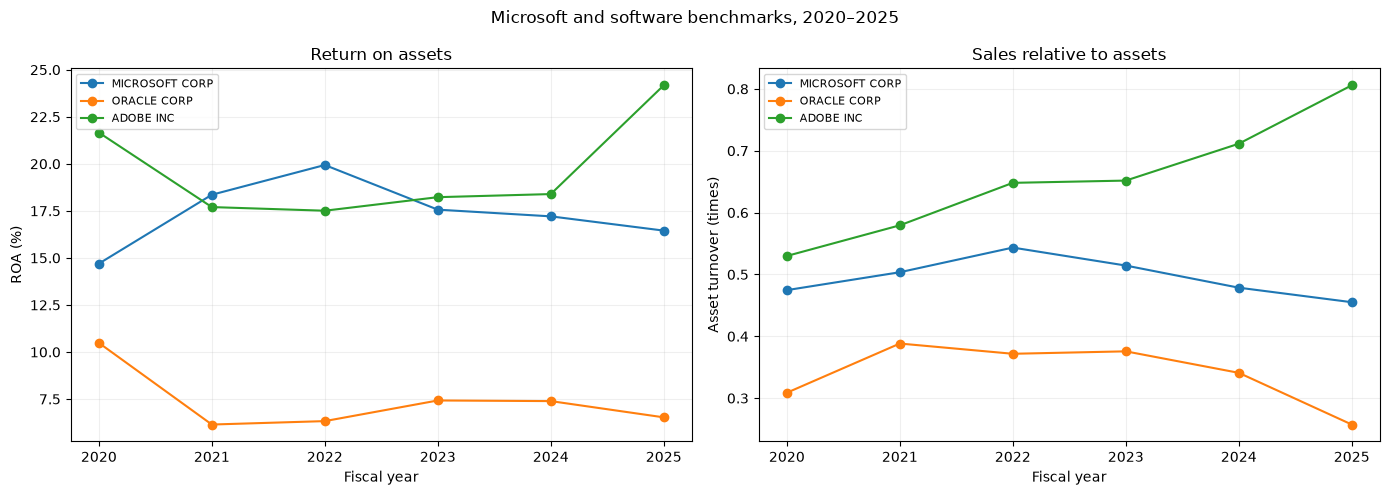

,Microsoft diagnostic
sales_cagr_2022_2025_percent,12.423
asset_cagr_2022_2025_percent,19.270
roa_change_percentage_points,-3.486
asset_turnover_2022,0.543
asset_turnover_2025,0.455
net_margin_2022_percent,36.686
net_margin_2025_percent,36.146


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for firm_id, observations in case_panel.groupby("gvkey"):
    name = observations["conm"].iloc[-1]
    axes[0].plot(observations["fyear"], 100 * observations["case_roa"], marker="o", label=name)
    axes[1].plot(observations["fyear"], observations["asset_turnover"], marker="o", label=name)
axes[0].set(title="Return on assets", xlabel="Fiscal year", ylabel="ROA (%)")
axes[1].set(title="Sales relative to assets", xlabel="Fiscal year", ylabel="Asset turnover (times)")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.suptitle("Microsoft and software benchmarks, 2020–2025")
fig.tight_layout()
plt.show()

microsoft_case = case_panel.loc[case_panel["gvkey"] == FOCAL_GVKEY].set_index("fyear")
base, latest = microsoft_case.loc[2022], microsoft_case.loc[2025]
case_diagnostics = pd.Series({
    "sales_cagr_2022_2025_percent": 100 * ((latest["sale"] / base["sale"]) ** (1 / 3) - 1),
    "asset_cagr_2022_2025_percent": 100 * ((latest["asset"] / base["asset"]) ** (1 / 3) - 1),
    "roa_change_percentage_points": 100 * (latest["case_roa"] - base["case_roa"]),
    "asset_turnover_2022": base["asset_turnover"],
    "asset_turnover_2025": latest["asset_turnover"],
    "net_margin_2022_percent": 100 * base["net_margin"],
    "net_margin_2025_percent": 100 * latest["net_margin"],
}, name="Microsoft diagnostic").to_frame()
display(case_diagnostics.round(3))



In [24]:
print("Microsoft 2020 ROA:", round(100 * microsoft_case.loc[2020, "case_roa"], 2), "%")
print("Microsoft 2022 ROA:", round(100 * base["case_roa"], 2), "%")
print("Microsoft 2025 ROA:", round(100 * latest["case_roa"], 2), "%")
print("2022–2025 revenue CAGR:", round(case_diagnostics.loc["sales_cagr_2022_2025_percent"].iloc[0], 2), "%")
print("2022–2025 asset CAGR:", round(case_diagnostics.loc["asset_cagr_2022_2025_percent"].iloc[0], 2), "%")
print("2022–2025 ROA change:", round(case_diagnostics.loc["roa_change_percentage_points"].iloc[0], 2), "percentage points")
print("Asset turnover:", round(base["asset_turnover"], 3), "to", round(latest["asset_turnover"], 3))
print("Net margin:", round(100 * base["net_margin"], 2), "% to", round(100 * latest["net_margin"], 2), "%")


Microsoft 2020 ROA: 14.7 %
Microsoft 2022 ROA: 19.94 %
Microsoft 2025 ROA: 16.45 %
2022–2025 revenue CAGR: 12.42 %
2022–2025 asset CAGR: 19.27 %
2022–2025 ROA change: -3.49 percentage points
Asset turnover: 0.543 to 0.455
Net margin: 36.69 % to 36.15 %


**Interpretation.** Compare the printed rates and the chart: faster asset growth alongside declining turnover is consistent with slower revenue generation per unit of reported assets. Relatively stable net margin helps distinguish the turnover issue from a large profitability-margin change. The identity is an arithmetic relationship, not a causal model. Assets can precede future revenue, and acquisitions or accounting changes may alter the denominator.

### 4.4 One strategy suggestion

**Recommendation: strengthen milestone-based capital allocation for major asset expansions.** Before releasing subsequent funding tranches, assess whether existing projects are meeting their planned utilization and revenue milestones. Prioritize commitments with credible demand and deployment evidence, using the aggregate asset-productivity trend as a signal to investigate—not as a rule to stop long-term investment.

The evidence is a growing gap between asset growth and revenue growth, lower asset turnover, and relatively stable margin. The proposed action addresses that gap without assuming which product or investment caused it.

**Success measure:** Track revenue growth relative to asset growth and the direction of asset turnover and ROA over the next two fiscal years. Evaluate project-level utilization and revenue milestones at each funding review. Stabilizing asset turnover while maintaining commercially justified growth would support the action; use project hurdle rates and investment horizons to set targets rather than adopting Adobe's ratios.

**Qualification:** The dataset does not contain capital expenditure, asset composition, segment performance or utilization. The recommendation is to strengthen the evaluation process; it is not evidence that Microsoft lacks such a process or that a specific investment should be cut. Validate the diagnosis with segment and project information before implementation.

**Interpretation guardrail:** Use the full 2020–2025 ROA series as context. The 2022–2025 window examines a decline from a local peak, rather than implying ROA fell throughout the entire period. The proposed action is a hypothesis supported by aggregate ratios, not proof of a deficient existing investment process.

## 5 Limitations and attribution

### Methodological limits

- Financial and disclosure coverage differ. The corresponding year labels are matched without filing-date alignment.
- CIK joins preserve financial GVKEY as the firm identifier; conflicting filing mappings are retained for inspection.
- The longest-disclosure rule is deterministic but cannot identify the latest filing without accession/date metadata.
- Financial means can be sensitive to extreme values and changes in sample composition. No missing financial values are imputed.
- Keyword counts weight longer disclosures more heavily. NLTK stopwords leave generic business terms in the corpus.
- Separate TF-IDF and word2vec fits are descriptive comparisons; vocabulary, document coverage and model stochasticity affect results.

- Supplied fiscal-year labels may cover different calendar periods across companies. Confirm year conventions and monetary units before making external financial claims.
- Peer-sales shares describe only Microsoft, Oracle and Adobe; they are not industry market shares.

### Source provenance and AI assistance

Source data: the four supplied BAIT 508 public-firm and 10-K datasets. Verify their units and redistribution permissions before publishing data.

ChatGPT assisted with notebook structure, preparation code, integration of the contributors' notebooks, correction of industry filters and counting logic, completion of per-firm keyword extraction, and code/documentation review. The notebook uses calculations tied to the selected sector. Contributors remain responsible for reviewing and interpreting regenerated results. No unverified date is assigned to earlier AI assistance.
